## 1. Import Library


In [1]:
import json
import math
import os
import random
import time
from pathlib import Path

ROOT_DIR = Path.cwd()

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from IPython.display import display
from scipy import linalg
from sklearn.model_selection import train_test_split
from tensorflow.keras import layers
from tensorflow.keras.applications import InceptionV3
from tensorflow.keras.applications.inception_v3 import (
    preprocess_input as inception_preprocess_input,
)

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
if gpus:
    try:
        for gpu in gpus:
            tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as error:
        print(f"Pengaturan memory growth dilewati: {error}")

print("TensorFlow version:", tf.__version__)
print("GPU tersedia      :", len(gpus))


I0000 00:00:1785860559.351672   34367 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


TensorFlow version: 2.21.0
GPU tersedia      : 1


In [2]:
print("=" * 50)
print("DEVICE INFORMATION")
print("=" * 50)

physical_devices = tf.config.list_physical_devices()
print(f"\nSemua perangkat fisik yang terdeteksi:")
for device in physical_devices:
    print(f"  - {device.device_type}: {device.name}")

gpus = tf.config.list_physical_devices("GPU")
cpus = tf.config.list_physical_devices("CPU")

if gpus:
    print(f"\nTraining akan menggunakan GPU ({len(gpus)} device)")
    for gpu in gpus:
        print(f"  - {gpu.name}")
else:
    print(f"\nTidak ada GPU terdeteksi. Training akan menggunakan CPU.")
    for cpu in cpus:
        print(f"  - {cpu.name}")

print(f"\nDevice default: {tf.test.gpu_device_name() or 'CPU'}")
print("=" * 50)


DEVICE INFORMATION

Semua perangkat fisik yang terdeteksi:
  - CPU: /physical_device:CPU:0
  - GPU: /physical_device:GPU:0

Training akan menggunakan GPU (1 device)
  - /physical_device:GPU:0

Device default: /device:GPU:0


I0000 00:00:1785860618.609462   34367 gpu_device.cc:2043] Created device /device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [3]:
RUN_NAME = "dcgan_ncd_128"
RUN_TIMESTAMP = time.strftime("%Y%m%d_%H%M%S")

OUTPUT_BASE_DIR = ROOT_DIR / "dcgan_outputs" / RUN_NAME
OUTPUT_DIR = OUTPUT_BASE_DIR / RUN_TIMESTAMP

suffix = 1
while OUTPUT_DIR.exists():
    OUTPUT_DIR = OUTPUT_BASE_DIR / f"{RUN_TIMESTAMP}_{suffix:02d}"
    suffix += 1

SAMPLE_DIR = OUTPUT_DIR / "samples"
SYNTHETIC_DIR = OUTPUT_DIR / "synthetic_ncd_128"
CHECKPOINT_DIR = OUTPUT_DIR / "checkpoints"
LOG_DIR = OUTPUT_DIR / "logs"

GENERATOR_PATH = OUTPUT_DIR / "dcgan_generator_ncd_final.keras"
DISCRIMINATOR_PATH = OUTPUT_DIR / "dcgan_discriminator_ncd_final.keras"
HISTORY_PATH = LOG_DIR / "dcgan_training_history.csv"
FID_PATH = LOG_DIR / "dcgan_fid_checkpoints.csv"
TRAINING_CONFIG_PATH = LOG_DIR / "dcgan_training_config.json"

for directory in [OUTPUT_DIR, SAMPLE_DIR, SYNTHETIC_DIR, CHECKPOINT_DIR, LOG_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Output directory:", OUTPUT_DIR)


Output directory: /mnt/d/UNIKOM/Semester 8/New folder (2)/dcgan_outputs/dcgan_ncd_128/20260804_232338


## 2. Load Dataset

Dataset dibagi secara stratified menjadi data latih (80%) dan data uji (20%). DCGAN hanya dilatih menggunakan kelas minoritas NCD dari data latih.


In [4]:
DATASET_DIR = ROOT_DIR / "DATASET"
CLASS_NAMES = ["cocci", "healthy", "ncd", "salmo"]
MINORITY_CLASS = "ncd"
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png"}
TEST_SIZE = 0.20

records = []

for class_name in CLASS_NAMES:
    class_directory = DATASET_DIR / class_name
    if not class_directory.exists():
        raise FileNotFoundError(f"Folder kelas tidak ditemukan: {class_directory}")

    for image_path in sorted(class_directory.iterdir()):
        if image_path.is_file() and image_path.suffix.lower() in IMAGE_EXTENSIONS:
            records.append(
                {
                    "filepath": str(image_path),
                    "label": class_name,
                }
            )

dataset_df = pd.DataFrame(records)
if dataset_df.empty:
    raise ValueError(f"Tidak ada citra yang ditemukan di {DATASET_DIR}")

train_df, test_df = train_test_split(
    dataset_df,
    test_size=TEST_SIZE,
    stratify=dataset_df["label"],
    random_state=SEED,
)

train_df = train_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

ncd_train_df = train_df[train_df["label"] == MINORITY_CLASS].reset_index(
    drop=True
)
ncd_paths = ncd_train_df["filepath"].to_numpy()

if len(ncd_paths) == 0:
    raise ValueError("Data latih kelas NCD kosong.")

print("Total citra       :", len(dataset_df))
print("Data latih        :", len(train_df))
print("Data uji          :", len(test_df))
print("NCD untuk DCGAN   :", len(ncd_paths))
print()
print("Distribusi data latih:")
display(train_df["label"].value_counts().rename("jumlah").to_frame())


Total citra       : 6812
Data latih        : 5449
Data uji          : 1363
NCD untuk DCGAN   : 301

Distribusi data latih:


,jumlah
label,
salmo,1821
cocci,1682
healthy,1645
ncd,301


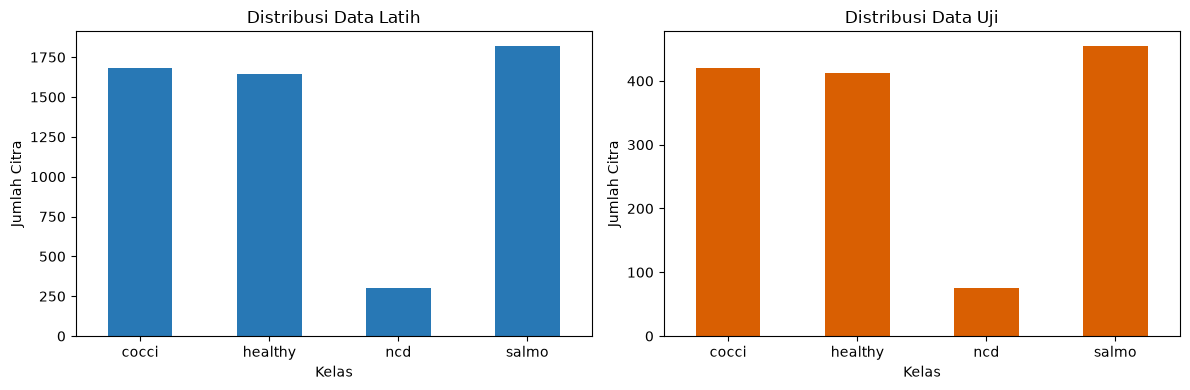

In [5]:
train_counts = train_df["label"].value_counts().reindex(CLASS_NAMES)
test_counts = test_df["label"].value_counts().reindex(CLASS_NAMES)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

train_counts.plot.bar(ax=axes[0], color="#2878B5")
axes[0].set_title("Distribusi Data Latih")
axes[0].set_xlabel("Kelas")
axes[0].set_ylabel("Jumlah Citra")
axes[0].tick_params(axis="x", rotation=0)

test_counts.plot.bar(ax=axes[1], color="#D95F02")
axes[1].set_title("Distribusi Data Uji")
axes[1].set_xlabel("Kelas")
axes[1].set_ylabel("Jumlah Citra")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


## 3. Preprocessing

Citra diubah menjadi RGB, di-resize ke 128 × 128 piksel, lalu dinormalisasi dari rentang `[0, 255]` ke `[-1, 1]` agar sesuai dengan aktivasi `tanh` pada output generator.


In [6]:
IMAGE_SIZE = (128, 128)
BATCH_SIZE = 32


def load_and_preprocess_image(filepath):
    image_bytes = tf.io.read_file(filepath)
    image = tf.image.decode_image(
        image_bytes,
        channels=3,
        expand_animations=False,
    )
    image.set_shape([None, None, 3])
    image = tf.cast(image, tf.float32)
    image = tf.image.resize(
        image,
        IMAGE_SIZE,
        method="bilinear",
        antialias=True,
    )
    image = (image - 127.5) / 127.5
    return tf.ensure_shape(image, (*IMAGE_SIZE, 3))


def make_dcgan_dataset(
    image_paths,
    batch_size=BATCH_SIZE,
    shuffle=True,
    cache=True,
):
    if len(image_paths) == 0:
        raise ValueError("Daftar path citra untuk DCGAN kosong.")

    dataset = tf.data.Dataset.from_tensor_slices(image_paths)
    dataset = dataset.map(load_and_preprocess_image)

    if cache:
        dataset = dataset.cache()

    if shuffle:
        dataset = dataset.shuffle(
            buffer_size=len(image_paths),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    return dataset.batch(batch_size)


dcgan_dataset = make_dcgan_dataset(ncd_paths)
sample_batch = next(iter(dcgan_dataset))

print("Batch shape :", sample_batch.shape)
print(
    "Rentang nilai:",
    f"{tf.reduce_min(sample_batch).numpy():.3f}",
    "sampai",
    f"{tf.reduce_max(sample_batch).numpy():.3f}",
)


I0000 00:00:1785860639.026532   34367 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1763 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


Batch shape : (32, 128, 128, 3)
Rentang nilai: -1.000 sampai 1.000


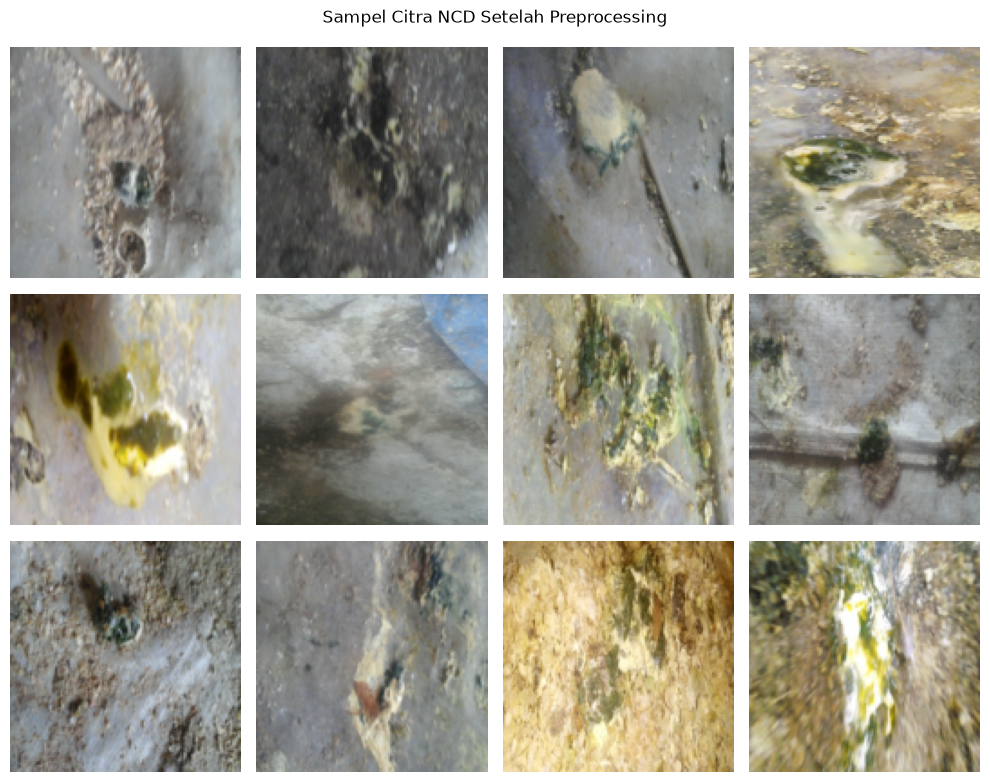

In [7]:
def denormalize_images(images):
    return np.clip((np.asarray(images) + 1.0) / 2.0, 0.0, 1.0)


preview_images = denormalize_images(sample_batch[:12].numpy())

fig, axes = plt.subplots(3, 4, figsize=(10, 8))
for index, axis in enumerate(axes.flat):
    axis.imshow(preview_images[index])
    axis.axis("off")

fig.suptitle("Sampel Citra NCD Setelah Preprocessing")
plt.tight_layout()
plt.show()


## 4. Pemodelan DCGAN

Generator menggunakan `Conv2DTranspose`, Batch Normalization, dan ReLU untuk mengubah noise vector menjadi citra RGB 128 × 128. Discriminator menggunakan strided `Conv2D`, Batch Normalization, LeakyReLU, dan Dropout.

Bobot convolution diinisialisasi dari distribusi normal dengan mean `0.0` dan standar deviasi `0.02` mengikuti konvensi DCGAN.


In [8]:
LATENT_DIM = 100

def make_generator_model(latent_dim=LATENT_DIM):
    model = tf.keras.Sequential(name='generator')
    model.add(layers.Input(shape=(latent_dim,), name="noise"))

    # Project & reshape: z → (8, 8, 512)
    model.add(layers.Dense(8 * 8 * 512, use_bias=False))
    model.add(layers.Reshape((8, 8, 512)))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    # Layer 1: (8,8,512) → (16,16,256)
    model.add(layers.Conv2DTranspose(256, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    # Layer 2: (16,16,256) → (32,32,128)
    model.add(layers.Conv2DTranspose(128, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    # Layer 3: (32,32,128) → (64,64,64)
    model.add(layers.Conv2DTranspose(64, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.ReLU())

    # Layer 4 (output): (64,64,64) → (128,128,3)
    model.add(layers.Conv2DTranspose(3, kernel_size=5, strides=2, padding='same', use_bias=False, activation='tanh', name="generated_image"))

    return model

generator = make_generator_model()
generator.summary()


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 32768)          │     3,276,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 256)    │     2,097,152 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 64, 64, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_3 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ generated_image                 │ (None, 128, 128, 3)    │         4,800 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,037,952 (23.03 MB)

 Trainable params: 6,036,032 (23.03 MB)

 Non-trainable params: 1,920 (7.50 KB)

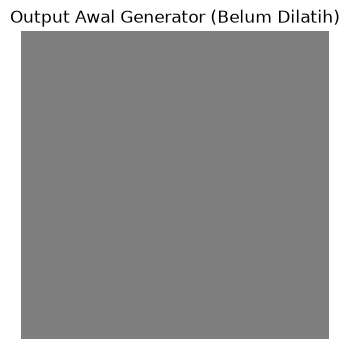

Output generator: (1, 128, 128, 3)


In [10]:
def generate_images(model, num_images, batch_size=32):
    generated_batches = []

    for start in range(0, num_images, batch_size):
        current_batch_size = min(batch_size, num_images - start)
        noise = tf.random.normal([current_batch_size, LATENT_DIM])
        generated_batches.append(model(noise, training=False))

    return tf.concat(generated_batches, axis=0)


test_noise = tf.random.normal([1, LATENT_DIM], seed=SEED)
generated_image = generator(test_noise, training=False)

plt.figure(figsize=(4, 4))
plt.imshow(denormalize_images(generated_image[0].numpy()))
plt.title("Output Awal Generator (Belum Dilatih)")
plt.axis("off")
plt.show()

print("Output generator:", generated_image.shape)


In [11]:
def make_discriminator_model(input_shape=(128, 128, 3)):
    model = tf.keras.Sequential(name='discriminator')
    model.add(layers.Input(shape=input_shape, name="input_image"))

    # Layer 1: (128,128,3) → (64,64,64)
    model.add(layers.Conv2D(64, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # Layer 2: (64,64,64) → (32,32,128)
    model.add(layers.Conv2D(128, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # Layer 3: (32,32,128) → (16,16,256)
    model.add(layers.Conv2D(256, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # Layer 4: (16,16,256) → (8,8,512)
    model.add(layers.Conv2D(512, kernel_size=4, strides=2, padding='same', use_bias=False))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # Output: Flatten → 1
    model.add(layers.Flatten())
    model.add(layers.Dense(1, activation='sigmoid'))

    return model

def dcgan_weight_init(model):
    for layer in model.layers:
        if isinstance(layer, (layers.Conv2D, layers.Conv2DTranspose, layers.Dense)):
            if hasattr(layer, 'kernel') and layer.kernel is not None:
                layer.kernel.assign(
                    tf.random.normal(layer.kernel.shape, mean=0.0, stddev=0.02)
                )
        elif isinstance(layer, layers.BatchNormalization):
            if hasattr(layer, 'gamma') and layer.gamma is not None:
                layer.gamma.assign(
                    tf.random.normal(layer.gamma.shape, mean=1.0, stddev=0.02)
                )
            if hasattr(layer, 'beta') and layer.beta is not None:
                layer.beta.assign(tf.zeros(layer.beta.shape))

discriminator = make_discriminator_model()

# Inisialisasi bobot sesuai paper
dcgan_weight_init(generator)
dcgan_weight_init(discriminator)

discriminator.summary()

initial_probability = discriminator(
    generated_image,
    training=False
)


print("Probabilitas real:", float(initial_probability[0, 0]))

# Simpan arsitektur model
with open(OUTPUT_DIR / "model_architecture_summary.txt", "w", encoding="utf-8") as f:
    f.write("=== GENERATOR ===\n")
    generator.summary(print_fn=lambda x: f.write(x + "\n"))
    f.write("\n=== DISCRIMINATOR ===\n")
    discriminator.summary(print_fn=lambda x: f.write(x + "\n"))


Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 64)     │         3,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 128)    │       131,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 256)    │       524,288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 512)      │     2,097,152 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 8, 8, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 8, 8, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 32768)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │        32,769 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,791,937 (10.65 MB)

 Trainable params: 2,790,145 (10.64 MB)

 Non-trainable params: 1,792 (7.00 KB)

Probabilitas real: 0.49995774030685425


## 5. Pelatihan


In [12]:
cross_entropy = tf.keras.losses.BinaryCrossentropy()


def discriminator_loss(real_predictions, fake_predictions):
    # Label Smoothing: citra asli = 0.9, citra sintetis = 0.1
    real_loss = cross_entropy(tf.ones_like(real_predictions) * 0.9, real_predictions)
    fake_loss = cross_entropy(tf.ones_like(fake_predictions) * 0.1, fake_predictions)
    return real_loss + fake_loss


def generator_loss(fake_predictions):
    return cross_entropy(tf.ones_like(fake_predictions), fake_predictions)


generator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0002,
    beta_1=0.5,
    beta_2=0.999,
)
discriminator_optimizer = tf.keras.optimizers.Adam(
    learning_rate=0.0001,
    beta_1=0.5,
    beta_2=0.999,
)

checkpoint_epoch = tf.Variable(0, dtype=tf.int64)
checkpoint = tf.train.Checkpoint(
    epoch=checkpoint_epoch,
    generator=generator,
    discriminator=discriminator,
    generator_optimizer=generator_optimizer,
    discriminator_optimizer=discriminator_optimizer,
)
checkpoint_manager = tf.train.CheckpointManager(
    checkpoint,
    directory=str(CHECKPOINT_DIR),
    max_to_keep=50,
)

fixed_noise = tf.random.normal(
    [16, LATENT_DIM],
    seed=SEED,
)


In [14]:
@tf.function
def train_step(real_images):
    current_batch_size = tf.shape(real_images)[0]
    noise = tf.random.normal([current_batch_size, LATENT_DIM])

    with tf.GradientTape() as generator_tape, tf.GradientTape() as discriminator_tape:
        fake_images = generator(noise, training=True)

        real_predictions = discriminator(real_images, training=True)
        fake_predictions = discriminator(fake_images, training=True)

        gen_loss = generator_loss(fake_predictions)
        disc_loss = discriminator_loss(real_predictions, fake_predictions)

    generator_gradients = generator_tape.gradient(
        gen_loss,
        generator.trainable_variables,
    )
    discriminator_gradients = discriminator_tape.gradient(
        disc_loss,
        discriminator.trainable_variables,
    )

    generator_optimizer.apply_gradients(
        zip(generator_gradients, generator.trainable_variables)
    )
    discriminator_optimizer.apply_gradients(
        zip(discriminator_gradients, discriminator.trainable_variables)
    )

    real_score = tf.reduce_mean(real_predictions)
    fake_score = tf.reduce_mean(fake_predictions)
    return gen_loss, disc_loss, real_score, fake_score


In [15]:
def generate_and_save_images(model, epoch, test_input):
    predictions = model(test_input, training=False)
    predictions = denormalize_images(predictions.numpy())

    columns = int(math.sqrt(len(predictions)))
    rows = math.ceil(len(predictions) / columns)
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(columns * 2.2, rows * 2.2),
    )
    axes = np.asarray(axes).reshape(-1)

    for index, axis in enumerate(axes):
        axis.axis("off")
        if index < len(predictions):
            axis.imshow(predictions[index])

    fig.suptitle(f"Epoch {epoch}")
    plt.tight_layout()

    sample_path = SAMPLE_DIR / f"image_at_epoch_{epoch:04d}.png"
    fig.savefig(sample_path, dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return sample_path


def train(dataset, epochs):
    history = []
    checkpoint_epoch.assign(0)
    start_epoch = 0

    print("Memulai training DCGAN...")

    for epoch in range(start_epoch + 1, epochs + 1):
        start_time = time.time()
        generator_metric = tf.keras.metrics.Mean()
        discriminator_metric = tf.keras.metrics.Mean()
        real_score_metric = tf.keras.metrics.Mean()
        fake_score_metric = tf.keras.metrics.Mean()

        for image_batch in dataset:
            gen_loss, disc_loss, real_score, fake_score = train_step(
                image_batch
            )
            generator_metric.update_state(gen_loss)
            discriminator_metric.update_state(disc_loss)
            real_score_metric.update_state(real_score)
            fake_score_metric.update_state(fake_score)

        checkpoint_epoch.assign(epoch)

        epoch_result = {
            "epoch": epoch,
            "generator_loss": float(generator_metric.result().numpy()),
            "discriminator_loss": float(
                discriminator_metric.result().numpy()
            ),
            "d_real": float(real_score_metric.result().numpy()),
            "d_fake": float(fake_score_metric.result().numpy()),
            "seconds": round(time.time() - start_time, 3),
        }
        history.append(epoch_result)

        sample_path = None
        if epoch == 1 or epoch % 50 == 0 or epoch == epochs:
            sample_path = generate_and_save_images(
                generator,
                epoch,
                fixed_noise,
            )

        if epoch % 50 == 0 or epoch == epochs:
            checkpoint_manager.save(checkpoint_number=epoch)

        pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)

        message = (
            f"Epoch {epoch:03d}/{epochs} | "
            f"Loss G: {epoch_result['generator_loss']:.4f} | "
            f"Loss D: {epoch_result['discriminator_loss']:.4f} | "
            f"D(x): {epoch_result['d_real']:.4f} | "
            f"D(G(z)): {epoch_result['d_fake']:.4f} | "
            f"{epoch_result['seconds']:.2f}s"
        )
        if sample_path is not None:
            message += f" | Sampel: {sample_path.name}"
        print(message)

    print("Riwayat training:", HISTORY_PATH)
    return pd.DataFrame(history)


In [ ]:
training_history_df = train(dcgan_dataset, epochs=1000)


In [16]:
if HISTORY_PATH.exists():
    history_df = pd.read_csv(HISTORY_PATH)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))

    axes[0].plot(
        history_df["epoch"],
        history_df["generator_loss"],
        label="Generator",
        color="#2878B5",
    )
    axes[0].plot(
        history_df["epoch"],
        history_df["discriminator_loss"],
        label="Discriminator",
        color="#D95F02",
    )
    axes[0].set_title("Loss DCGAN")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].grid(alpha=0.3)
    axes[0].legend()

    axes[1].plot(
        history_df["epoch"],
        history_df["d_real"],
        label="D(x) Real",
        color="#2CA02C",
    )
    axes[1].plot(
        history_df["epoch"],
        history_df["d_fake"],
        label="D(G(z)) Fake",
        color="#E7298A",
    )
    axes[1].set_title("Skor Discriminator")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Skor")
    axes[1].grid(alpha=0.3)
    axes[1].legend()

    plt.tight_layout()
    plt.show()

    last_epoch = history_df.iloc[-1]
    print("Epoch terakhir       :", int(last_epoch["epoch"]))
    print("Generator loss akhir :", f"{last_epoch['generator_loss']:.4f}")
    print("Discriminator akhir  :", f"{last_epoch['discriminator_loss']:.4f}")
else:
    print("Riwayat training belum tersedia.")


Riwayat training belum tersedia.


## 6. Evaluasi

Evaluasi dilakukan menggunakan metrik Frechet Inception Distance (FID) dengan 100 citra asli dan 100 citra sintetis. Setiap checkpoint dievaluasi, kemudian generator dengan FID terbaik (terendah) dipilih untuk menghasilkan citra sintetis final.


In [17]:



def collect_real_images_for_fid(dataset, max_images):
    batches = []
    total_images = 0

    for image_batch in dataset:
        batches.append(image_batch)
        total_images += int(image_batch.shape[0])
        if total_images >= max_images:
            break

    if not batches:
        raise ValueError("Dataset untuk evaluasi FID kosong.")

    images = tf.concat(batches, axis=0)[:max_images]
    images = tf.image.resize(images, (299, 299), method="bilinear")
    images = (images + 1.0) / 2.0 * 255.0
    return inception_preprocess_input(images)


def generate_fake_images_for_fid(generator_model, num_images):
    batches = []
    num_batches = math.ceil(num_images / 8)

    for _ in range(num_batches):
        noise = tf.random.normal([8, LATENT_DIM])
        fake_batch = generator_model(noise, training=False)
        batches.append(fake_batch)

    images = tf.concat(batches, axis=0)[:num_images]
    images = tf.image.resize(images, (299, 299), method="bilinear")
    images = (images + 1.0) / 2.0 * 255.0
    return inception_preprocess_input(images)


def calculate_frechet_distance(mu1, sigma1, mu2, sigma2, eps=1e-6):
    mu1 = np.atleast_1d(mu1)
    mu2 = np.atleast_1d(mu2)

    sigma1 = np.atleast_2d(sigma1)
    sigma2 = np.atleast_2d(sigma2)

    diff = mu1 - mu2

    covmean = linalg.sqrtm(sigma1.dot(sigma2))
    if isinstance(covmean, tuple):
        covmean = covmean[0]
        
    if not np.isfinite(covmean).all():
        offset = np.eye(sigma1.shape[0]) * eps
        covmean = linalg.sqrtm((sigma1 + offset).dot(sigma2 + offset))
        if isinstance(covmean, tuple):
            covmean = covmean[0]

    if np.iscomplexobj(covmean):
        covmean = covmean.real

    return diff.dot(diff) + np.trace(sigma1 + sigma2 - 2.0 * covmean)


In [18]:
with tf.device("/CPU:0"):
    inception_model = InceptionV3(
        include_top=False,
        pooling="avg",
        input_shape=(299, 299, 3),
        weights="imagenet",
    )

    print("Mengumpulkan 100 citra asli untuk FID...")
    real_images_for_fid = collect_real_images_for_fid(
        dcgan_dataset,
        100,
    )
    real_features = inception_model.predict(
        real_images_for_fid,
        batch_size=8,
        verbose=0,
    )
    mu_real = np.mean(real_features, axis=0)
    sigma_real = np.cov(real_features, rowvar=False)

    fid_results = []
    checkpoint_paths = [
        str(path).replace(".index", "")
        for path in CHECKPOINT_DIR.glob("ckpt-*.index")
    ]

    # Mengurutkan berdasarkan nomor epoch di nama file (ckpt-1, ckpt-2, dst)
    checkpoint_paths.sort(key=lambda x: int(x.split("-")[-1]))

    print(f"Mengevaluasi FID untuk {len(checkpoint_paths)} checkpoint:")

    eval_generator = make_generator_model()
    eval_checkpoint = tf.train.Checkpoint(generator=eval_generator)

    for path in checkpoint_paths:
        eval_checkpoint.restore(path).expect_partial()
        epoch_str = path.split("-")[-1]
        epoch_num = int(epoch_str)

        fake_images_for_fid = generate_fake_images_for_fid(
            eval_generator,
            100,
        )
        fake_features = inception_model.predict(
            fake_images_for_fid,
            batch_size=8,
            verbose=0,
        )

        mu_fake = np.mean(fake_features, axis=0)
        sigma_fake = np.cov(fake_features, rowvar=False)

        fid_score = calculate_frechet_distance(
            mu_real,
            sigma_real,
            mu_fake,
            sigma_fake,
        )

        fid_results.append(
            {
                "checkpoint": epoch_str,
                "epoch": epoch_num,
                "fid": fid_score,
                "path": path,
            }
        )
        print(f"  - Checkpoint {epoch_str} (Epoch {epoch_num}) | FID: {fid_score:.2f}")

    if fid_results:
        fid_df = pd.DataFrame(fid_results)
        fid_df.to_csv(FID_PATH, index=False)
        print("\nHasil FID disimpan di:", FID_PATH)
    else:
        print("Tidak ada checkpoint yang ditemukan untuk dievaluasi.")


Mengumpulkan 100 citra asli untuk FID...


I0000 00:00:1785871833.125877   34752 service.cc:153] XLA service 0x773e2c00a480 initialized for platform Host (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1785871833.128269   34752 service.cc:161]   StreamExecutor [0]: Host, Default Version (Driver: 0.0.0; Runtime: 0.0.0; Toolkit: 0.0.0; DNN: 0.0.0)
I0000 00:00:1785871833.506193   34752 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1785871836.145794   34752 device_compiler.h:208] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


Mengevaluasi FID untuk 0 checkpoint:
Tidak ada checkpoint yang ditemukan untuk dievaluasi.


In [ ]:
if FID_PATH.exists():
    fid_df = pd.read_csv(FID_PATH)
    best_checkpoint = fid_df.loc[fid_df["fid"].idxmin()]
    
    BEST_GENERATOR_PATH = best_checkpoint["path"]
    BEST_EPOCH = best_checkpoint["epoch"]
    BEST_FID = best_checkpoint["fid"]
    
    print("=== CHECKPOINT TERBAIK ===")
    print(f"Epoch : {BEST_EPOCH}")
    print(f"FID   : {BEST_FID:.2f}")
    
    # Load model terbaik ke best_generator
    best_generator = make_generator_model()
    best_checkpoint_reader = tf.train.Checkpoint(generator=best_generator)
    best_checkpoint_reader.restore(BEST_GENERATOR_PATH).expect_partial()
    
    # Optional: Simpan sebagai file .keras
    best_generator.save(OUTPUT_DIR / f"best_generator_epoch_{BEST_EPOCH}.keras")
else:
    print("Data evaluasi FID tidak ditemukan.")


Generate 1520 citra sintetis terbaik...
Berhasil menyimpan 1520 citra di:
/mnt/d/UNIKOM/Semester 8/New folder (2)/DATASET_NCD_SINTETIS


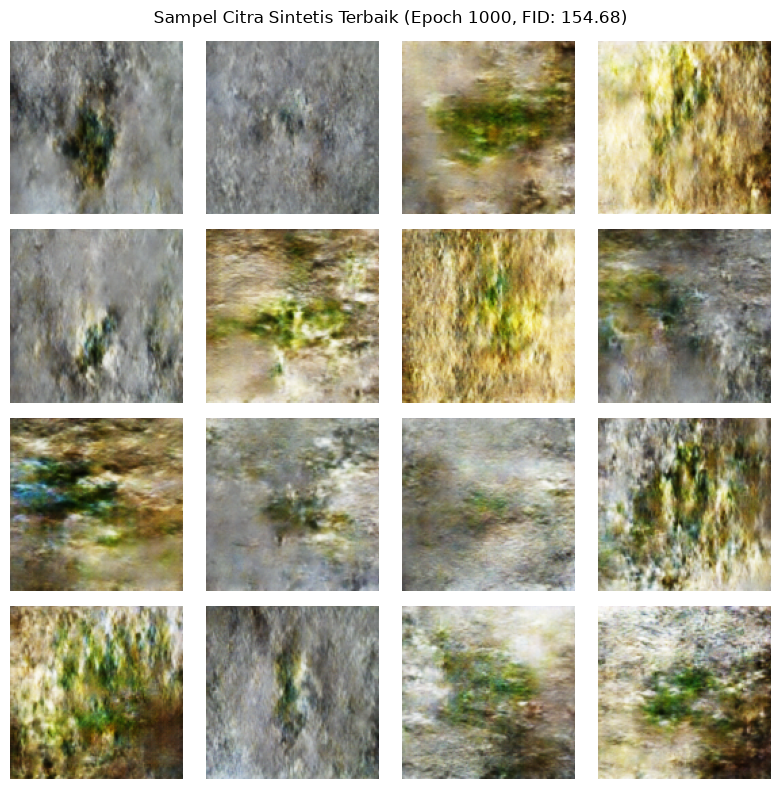

In [22]:
NUM_SYNTHETIC_TO_GENERATE = 1520

if 'best_generator' in locals():
    print(f"Generate {NUM_SYNTHETIC_TO_GENERATE} citra sintetis terbaik...")
    
    synthetic_images = []
    
    for _ in range(math.ceil(NUM_SYNTHETIC_TO_GENERATE / BATCH_SIZE)):
        noise = tf.random.normal([BATCH_SIZE, LATENT_DIM])
        fake_batch = best_generator(noise, training=False)
        synthetic_images.append(fake_batch)
        
    synthetic_images = tf.concat(synthetic_images, axis=0)[:NUM_SYNTHETIC_TO_GENERATE]
    synthetic_images = denormalize_images(synthetic_images.numpy())
    
    # Tentukan folder output final di luar dcgan_outputs
    FINAL_SYNTHETIC_DIR = ROOT_DIR / "DATASET_NCD_SINTETIS"
    FINAL_SYNTHETIC_DIR.mkdir(parents=True, exist_ok=True)
    
    # Simpan ke folder
    for i, img in enumerate(synthetic_images):
        save_path = FINAL_SYNTHETIC_DIR / f"synthetic_ncd_{i:03d}.png"
        tf.keras.utils.save_img(str(save_path), img)
        
    print(f"Berhasil menyimpan {NUM_SYNTHETIC_TO_GENERATE} citra di:")
    print(FINAL_SYNTHETIC_DIR)
    
    # Tampilkan beberapa contoh
    fig, axes = plt.subplots(4, 4, figsize=(8, 8))
    for i, ax in enumerate(axes.flat):
        if i < len(synthetic_images):
            ax.imshow(synthetic_images[i])
        ax.axis('off')
    
    fig.suptitle(f"Sampel Citra Sintetis Terbaik (Epoch {BEST_EPOCH}, FID: {BEST_FID:.2f})")
    plt.tight_layout()
    plt.show()
else:
    print("Model generator terbaik belum dimuat.")
